In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('WiFI_and_MQTT/balanced_dataset.csv')

In [3]:
df.head()

,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,Attack_Type,Label,Attack
0,695746.0,6.0,64.0,184.999355,184.999355,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,577.5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8217.0,1494.0,1494.0,1494.000000,0.000000,1494.0,1.667905e-03,5.5,54.662601,0.000000,0.000000,0.0,38.5,Spoofing,1,ARP Spoofing
1,3637961.1,17.0,64.0,173.228536,173.228536,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,2447.1,218.7,1144.0,534.579762,396.741844,347.9,6.082892e-03,5.5,32.138960,561.077696,175443.801999,0.9,38.5,Spoofing,1,ARP Spoofing
2,1702906.8,17.0,64.0,180.256940,180.256940,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1693.8,87.0,1034.8,302.935238,337.026851,262.4,6.571817e-03,5.5,24.147095,476.627944,140421.963059,0.9,38.5,Spoofing,1,ARP Spoofing
3,5339.5,6.0,119.0,0.088987,0.088987,0.0,0.0,0.0,0.0,0.5,1.0,0.0,0.0,0.0,0.0,0.0,70.1,0.0,0.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,476.5,55.2,111.6,83.336190,24.655715,84.3,9.981289e-02,5.5,12.879015,34.868446,729.505696,0.9,38.5,Spoofing,1,ARP Spoofing
4,2484636.8,17.0,64.0,180.866422,180.866422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,4405.8,102.6,686.0,284.489893,223.962943,304.0,1.694024e+08,13.5,23.888075,317.003649,50281.331821,1.0,244.6,Spoofing,1,ARP Spoofing


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

False

In [6]:
df.isnull().sum()

Header_Length      0
Protocol Type      0
Duration           0
Rate               0
Srate              0
Drate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
rst_count          0
HTTP               0
HTTPS              0
DNS                0
Telnet             0
SMTP               0
SSH                0
IRC                0
TCP                0
UDP                0
DHCP               0
ARP                0
ICMP               0
IGMP               0
IPv                0
LLC                0
Tot sum            0
Min                0
Max                0
AVG                0
Std                0
Tot size           0
IAT                0
Number             0
Magnitue           0
Radius             0
Covariance         0
Variance           0
Weight             0
Attack_Type        0
Label              0
Attack       

In [7]:
df.shape

(699409, 48)

In [4]:
df = df.drop(['Attack_Type', 'Label', 'Drate'], axis=1)

In [9]:
df.isnull().sum()

Header_Length      0
Protocol Type      0
Duration           0
Rate               0
Srate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
rst_count          0
HTTP               0
HTTPS              0
DNS                0
Telnet             0
SMTP               0
SSH                0
IRC                0
TCP                0
UDP                0
DHCP               0
ARP                0
ICMP               0
IGMP               0
IPv                0
LLC                0
Tot sum            0
Min                0
Max                0
AVG                0
Std                0
Tot size           0
IAT                0
Number             0
Magnitue           0
Radius             0
Covariance         0
Variance           0
Weight             0
Attack             0
dtype: int64

In [10]:
df['Attack'].unique()

array(['ARP Spoofing', 'DDoS ICMP Flood', 'DDoS SYN Flood',
       'DDoS TCP Flood', 'DDoS UDP Flood', 'DoS ICMP Flood',
       'DoS SYN Flood', 'DoS TCP Flood', 'DoS UDP Flood',
       'MQTT DDoS Connect Flood', 'MQTT DDoS Publish Flood',
       'MQTT DoS Connect Flood', 'MQTT DoS Publish Flood',
       'MQTT Malformed Data', 'Normal', 'OS Scan', 'Port Scan',
       'Vulnerability Scan'], dtype=object)

<h2>Outliers</h2>

In [5]:
df2 = df.copy()

In [6]:
df2 = df2.drop(['IGMP', 'IRC', 'SSH', 'SMTP', 'DHCP', 'Telnet', 'cwr_flag_number'], axis=1)

In [7]:
df2['Attack'].unique()

array(['ARP Spoofing', 'DDoS ICMP Flood', 'DDoS SYN Flood',
       'DDoS TCP Flood', 'DDoS UDP Flood', 'DoS ICMP Flood',
       'DoS SYN Flood', 'DoS TCP Flood', 'DoS UDP Flood',
       'MQTT DDoS Connect Flood', 'MQTT DDoS Publish Flood',
       'MQTT DoS Connect Flood', 'MQTT DoS Publish Flood',
       'MQTT Malformed Data', 'Normal', 'OS Scan', 'Port Scan',
       'Vulnerability Scan'], dtype=object)

In [8]:
attack_mapping = {
  'ARP Spoofing' : 1, 
    'DDoS ICMP Flood': 2, 
    'DDoS SYN Flood' : 3,
    'DDoS TCP Flood' : 4, 
    'DDoS UDP Flood' : 5, 
    'DoS ICMP Flood' : 6,
    'DoS SYN Flood' : 7, 
    'DoS TCP Flood' : 8, 
    'DoS UDP Flood' : 9,
    'MQTT DDoS Connect Flood' : 10, 
    'MQTT DDoS Publish Flood' : 11,
    'MQTT DoS Connect Flood' : 12, 
    'MQTT DoS Publish Flood' : 13,
    'MQTT Malformed Data' : 14, 
    'Normal': 0, 
    'OS Scan' : 15, 
    'Port Scan' : 16,
    'Vulnerability Scan' : 17
}

df2['Attack'] = df2['Attack'].apply(lambda x: attack_mapping[x])

In [9]:
df2['Attack'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14,  0, 15, 16,
       17], dtype=int64)

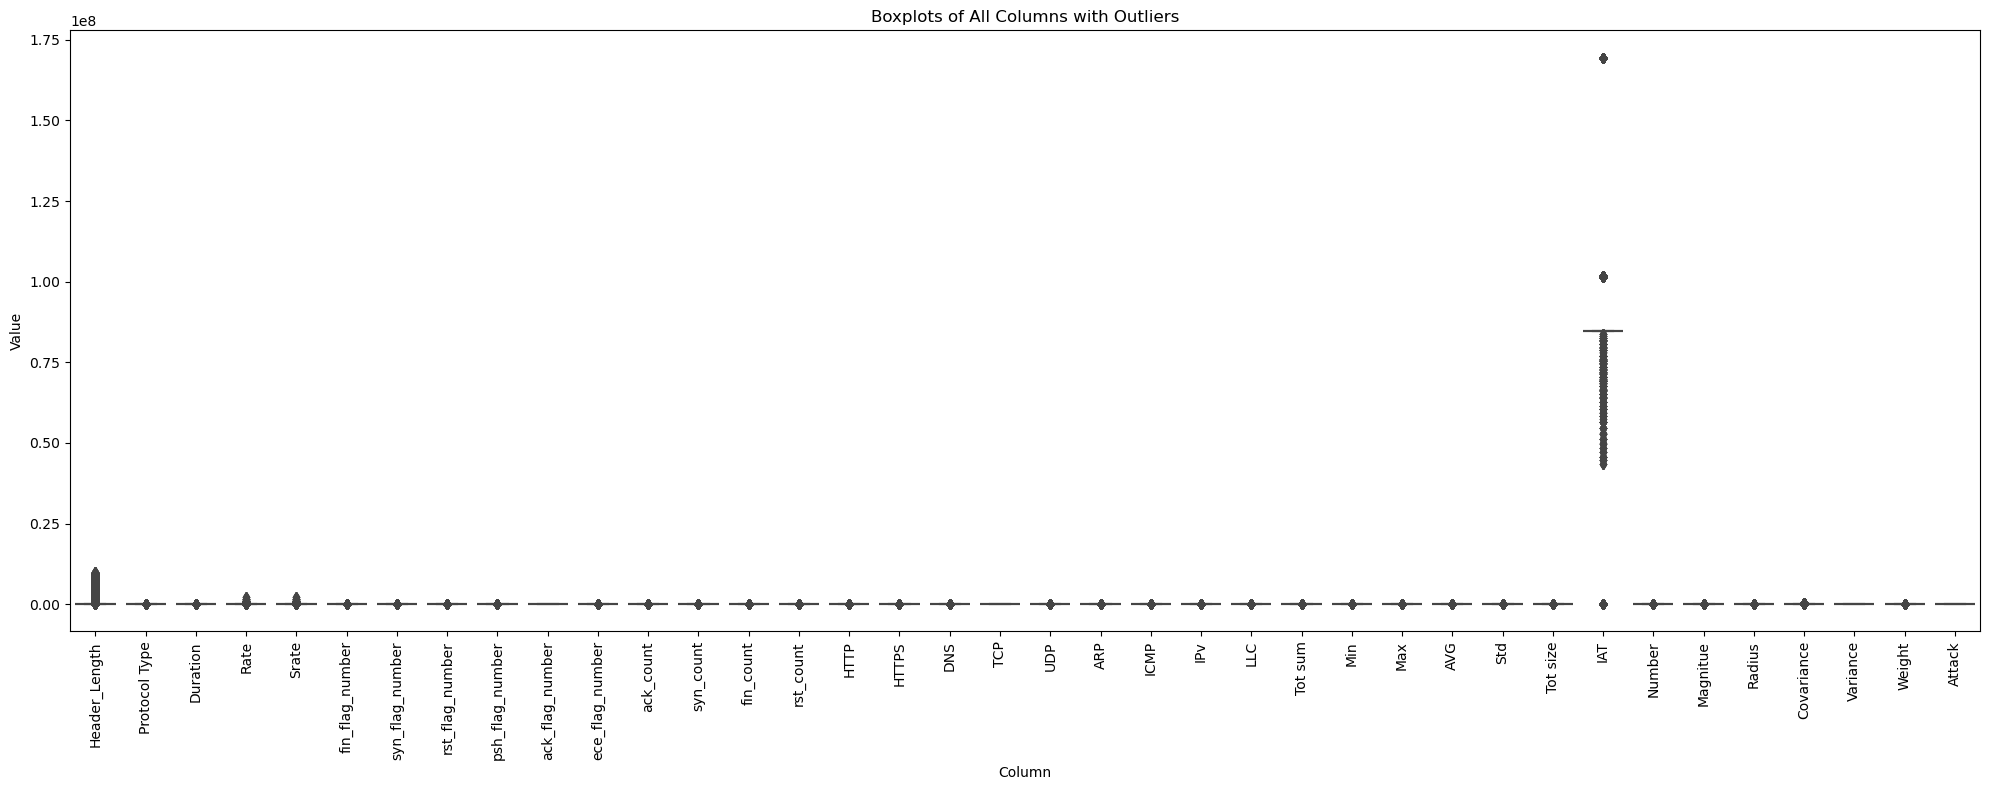

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

In [11]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [12]:
outliers_per_column

{'Header_Length': 85829,
 'Protocol Type': 255639,
 'Duration': 96835,
 'Rate': 153479,
 'Srate': 153479,
 'fin_flag_number': 81807,
 'syn_flag_number': 127119,
 'rst_flag_number': 173283,
 'psh_flag_number': 76002,
 'ack_flag_number': 0,
 'ece_flag_number': 211,
 'ack_count': 97887,
 'syn_count': 10449,
 'fin_count': 114115,
 'rst_count': 147680,
 'HTTP': 2889,
 'HTTPS': 38658,
 'DNS': 3306,
 'TCP': 0,
 'UDP': 160866,
 'ARP': 7281,
 'ICMP': 105416,
 'IPv': 7281,
 'LLC': 7281,
 'Tot sum': 117144,
 'Min': 90762,
 'Max': 138864,
 'AVG': 120572,
 'Std': 133343,
 'Tot size': 120304,
 'IAT': 148808,
 'Number': 148090,
 'Magnitue': 114424,
 'Radius': 133095,
 'Covariance': 151161,
 'Variance': 0,
 'Weight': 148125,
 'Attack': 0}

In [13]:
outliers_per_column.pop("Attack")
outliers_per_column

{'Header_Length': 85829,
 'Protocol Type': 255639,
 'Duration': 96835,
 'Rate': 153479,
 'Srate': 153479,
 'fin_flag_number': 81807,
 'syn_flag_number': 127119,
 'rst_flag_number': 173283,
 'psh_flag_number': 76002,
 'ack_flag_number': 0,
 'ece_flag_number': 211,
 'ack_count': 97887,
 'syn_count': 10449,
 'fin_count': 114115,
 'rst_count': 147680,
 'HTTP': 2889,
 'HTTPS': 38658,
 'DNS': 3306,
 'TCP': 0,
 'UDP': 160866,
 'ARP': 7281,
 'ICMP': 105416,
 'IPv': 7281,
 'LLC': 7281,
 'Tot sum': 117144,
 'Min': 90762,
 'Max': 138864,
 'AVG': 120572,
 'Std': 133343,
 'Tot size': 120304,
 'IAT': 148808,
 'Number': 148090,
 'Magnitue': 114424,
 'Radius': 133095,
 'Covariance': 151161,
 'Variance': 0,
 'Weight': 148125}

In [14]:
import numpy as np

# 1. Clean invalid values
df2['IAT'].replace([np.inf, -np.inf], np.nan, inplace=True)
df2['IAT'].fillna(df2['IAT'].median(), inplace=True)

# 2. Re-cap with more relaxed threshold
def cap_outliers_iqr(df2, column, factor=3.0):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    df2[column] = np.clip(df2[column], lower, upper)
    return df2

df2 = cap_outliers_iqr(df2, 'IAT', factor=3.0)

# 3. (Optional) Log transform if still skewed
df2['IAT'] = np.log1p(df2['IAT'])

In [22]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

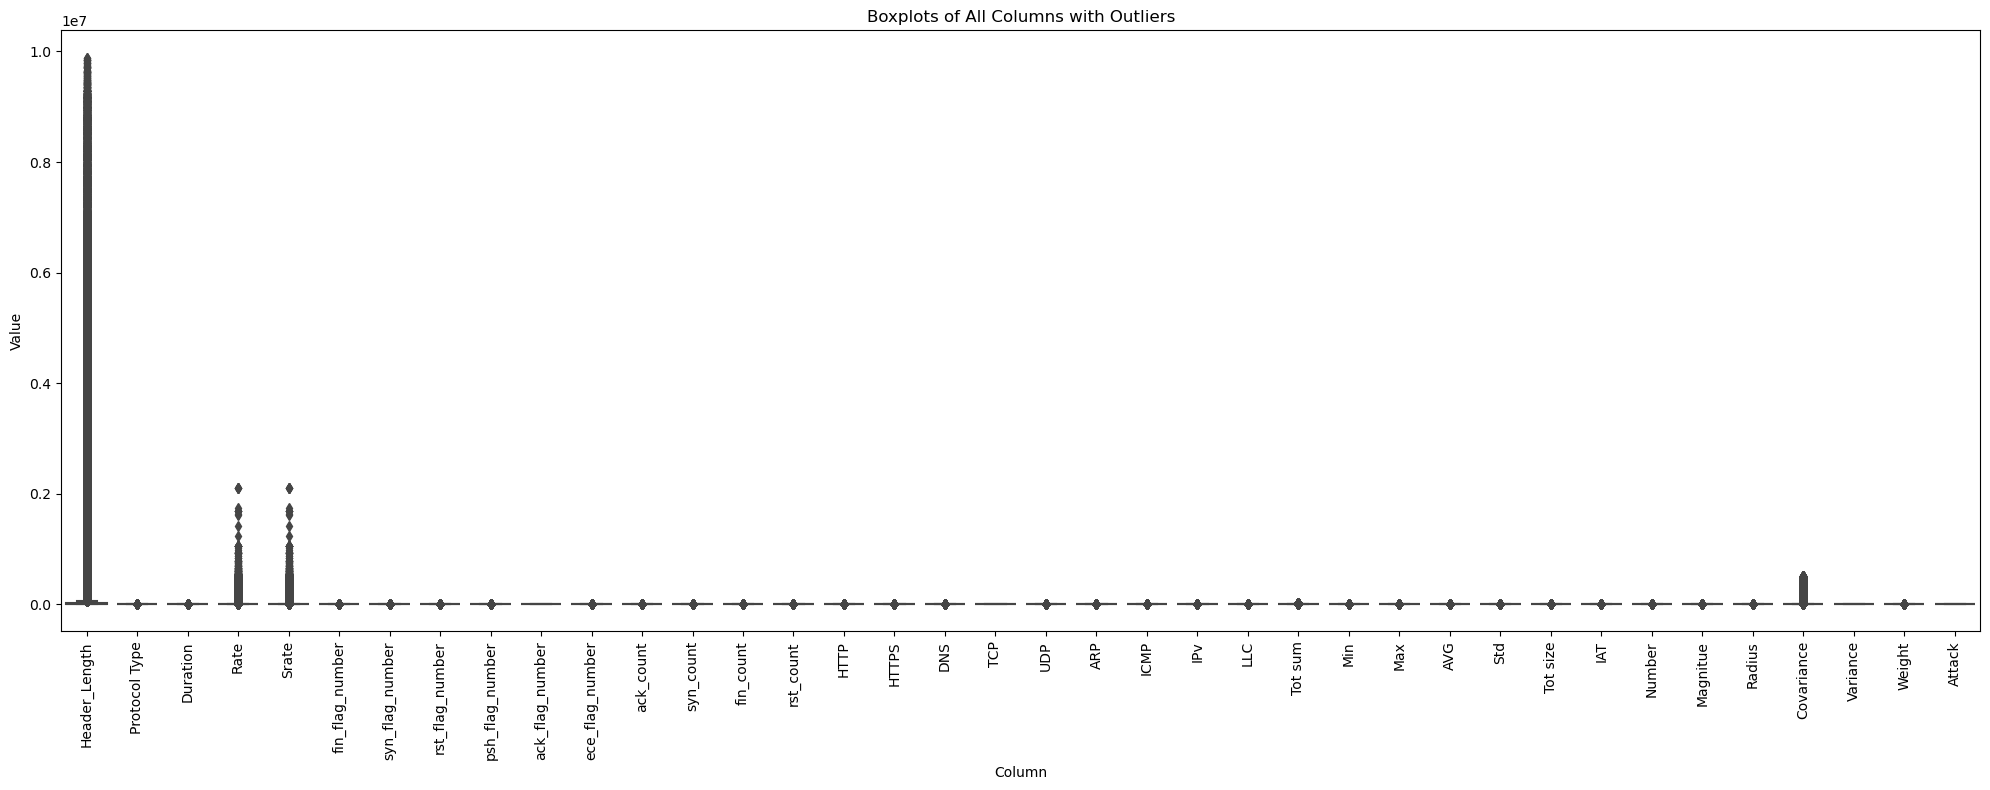

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

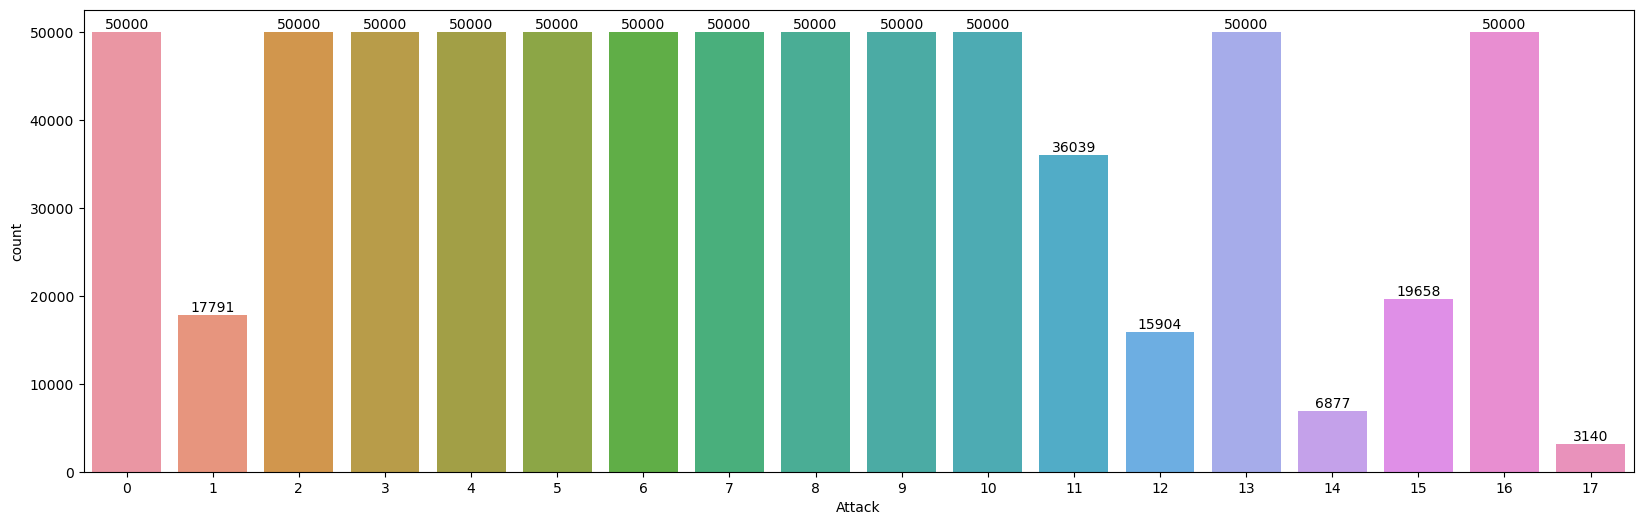

In [38]:
plt.figure(figsize=(20,6))
ax = sns.countplot(x='Attack',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [39]:
df2.shape

(699409, 38)

In [40]:
df2.columns

Index(['Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'TCP', 'UDP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'Attack'], dtype='object')

In [16]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Attack'])
y = df2['Attack']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Attack
5     40000
10    40000
9     40000
8     40000
16    40000
7     40000
3     40000
13    40000
0     40000
4     40000
6     40000
2     40000
11    28831
15    15726
1     14233
12    12723
14     5502
17     2512
Name: count, dtype: int64
Attack
5     40000
3     40000
15    40000
9     40000
17    40000
8     40000
16    40000
12    40000
7     40000
13    40000
1     40000
10    40000
0     40000
4     40000
11    40000
6     40000
2     40000
14    40000
Name: count, dtype: int64


<h2>ML Models</h2>


🔹 Training Logistic Regression...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Performance:
  Accuracy:  0.9293
  Precision: 0.9242
  Recall:    0.9293
  F1-score:  0.9191

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.91      0.86     10000
           1       0.61      0.67      0.64      3558
           2       1.00      1.00      1.00     10000
           3       1.00      1.00      1.00     10000
           4       1.00      1.00      1.00     10000
           5       1.00      1.00      1.00     10000
           6       1.00      1.00      1.00     10000
           7       0.98      1.00      0.99     10000
           8       1.00      1.00      1.00     10000
           9       1.00      1.00      1.00     10000
          10       0.97      0.99      0.98     10000
          11       0.99      0.82      0.89      7208
          12       0.98      0.93      0.95      3181
          13       0.88      0.99      0.93     10000
          14       0.64      0.40      0.49      13

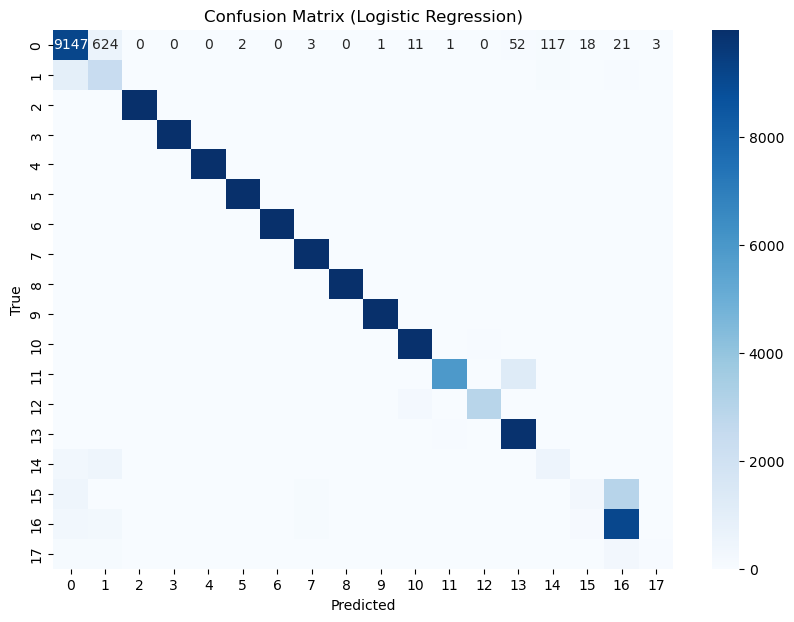


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.9739
  Precision: 0.9734
  Recall:    0.9739
  F1-score:  0.9736

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.96      0.94     10000
           1       0.84      0.86      0.85      3558
           2       1.00      1.00      1.00     10000
           3       1.00      1.00      1.00     10000
           4       1.00      1.00      1.00     10000
           5       1.00      1.00      1.00     10000
           6       1.00      1.00      1.00     10000
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       1.00      1.00      1.00     10000
          10       1.00      1.00      1.00     10000
          11       1.00      1.00      1.00      7208
          12       1.00      1.00      1.00      3181
          13       1.00      1.00      1.00     10000
          14       0.87     

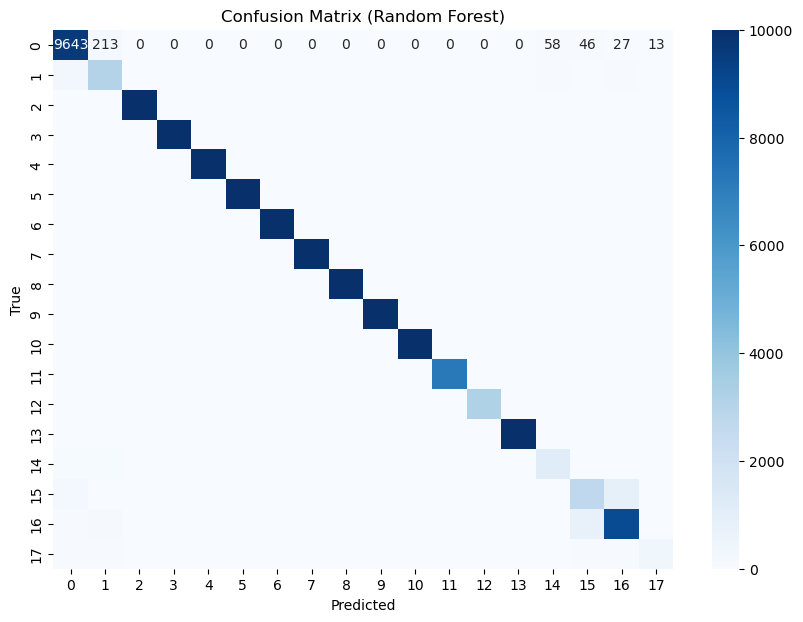


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [07:02:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.9730
  Precision: 0.9728
  Recall:    0.9730
  F1-score:  0.9728

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.97      0.94     10000
           1       0.84      0.84      0.84      3558
           2       1.00      1.00      1.00     10000
           3       1.00      1.00      1.00     10000
           4       1.00      1.00      1.00     10000
           5       1.00      1.00      1.00     10000
           6       1.00      1.00      1.00     10000
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       1.00      1.00      1.00     10000
          10       1.00      1.00      1.00     10000
          11       1.00      1.00      1.00      7208
          12       1.00      1.00      1.00      3181
          13       1.00      1.00      1.00     10000
          14       0.87      0.82      0.84      1375
         

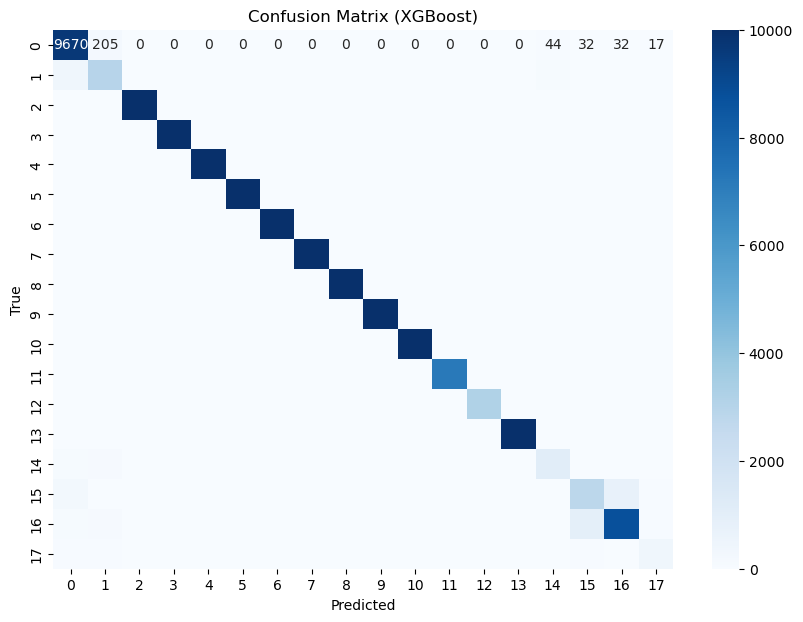


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.9471
  Precision: 0.9465
  Recall:    0.9471
  F1-score:  0.9460

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.93      0.90     10000
           1       0.69      0.73      0.71      3558
           2       1.00      1.00      1.00     10000
           3       1.00      0.99      1.00     10000
           4       1.00      1.00      1.00     10000
           5       1.00      1.00      1.00     10000
           6       1.00      1.00      1.00     10000
           7       0.99      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       1.00      1.00      1.00     10000
          10       0.98      0.99      0.99     10000
          11       0.97      0.84      0.90      7208
          12       0.98      0.94      0.96      3181
          13       0.90      0.98      0.94     10000
          14       0.68      0.64      0.66     

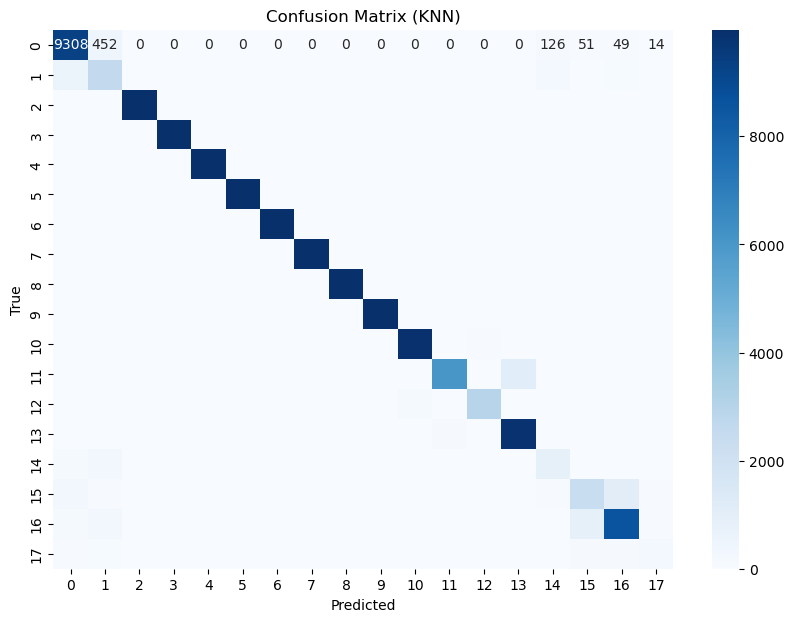


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.7062
  Precision: 0.7746
  Recall:    0.7062
  F1-score:  0.6651

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.64      0.76     10000
           1       0.59      0.47      0.53      3558
           2       0.51      0.98      0.67     10000
           3       0.61      0.99      0.75     10000
           4       1.00      0.98      0.99     10000
           5       0.52      0.98      0.68     10000
           6       0.81      0.06      0.11     10000
           7       0.98      0.33      0.49     10000
           8       0.99      0.97      0.98     10000
           9       0.80      0.08      0.15     10000
          10       0.93      0.79      0.85     10000
          11       0.96      0.81      0.88      7208
          12       0.58      0.91      0.71      3181
          13       0.88      0.98      0.93     10000
          14       0.26      0.7

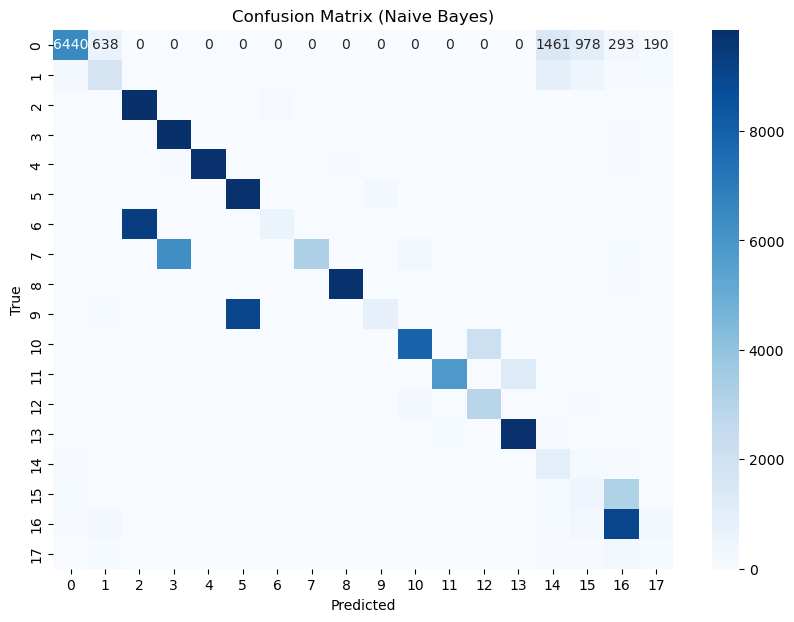


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.9476
  Precision: 0.9529
  Recall:    0.9476
  F1-score:  0.9463

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.88      0.87     10000
           1       0.52      0.80      0.63      3558
           2       1.00      1.00      1.00     10000
           3       1.00      0.99      0.99     10000
           4       1.00      0.99      0.99     10000
           5       1.00      0.99      1.00     10000
           6       1.00      1.00      1.00     10000
           7       0.99      0.99      0.99     10000
           8       1.00      1.00      1.00     10000
           9       0.97      1.00      0.98     10000
          10       1.00      1.00      1.00     10000
          11       1.00      0.99      0.99      7208
          12       1.00      1.00      1.00      3181
          13       1.00      0.99      1.00     10000
          14       0.97     

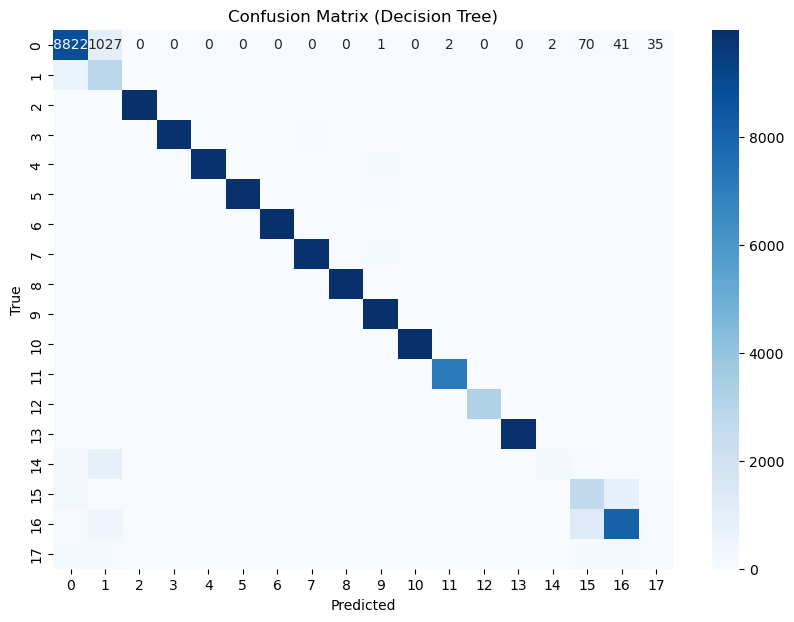


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.3545
  Precision: 0.3060
  Recall:    0.3545
  F1-score:  0.2212

Classification Report:
               precision    recall  f1-score   support

           0       0.26      0.97      0.41     10000
           1       0.00      0.00      0.00      3558
           2       0.50      1.00      0.67     10000
           3       0.00      0.00      0.00     10000
           4       0.00      0.00      0.00     10000
           5       0.51      0.99      0.67     10000
           6       0.60      0.00      0.00     10000
           7       0.30      0.00      0.01     10000
           8       0.19      0.97      0.32     10000
           9       0.57      0.01      0.02     10000
          10       0.83      0.95      0.89     10000
          11       0.00      0.00      0.00      7208
          12       0.00      0.00      0.00      3181
          13       0.00      0.00      0.00     10000
          14       0.00      0.00     

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

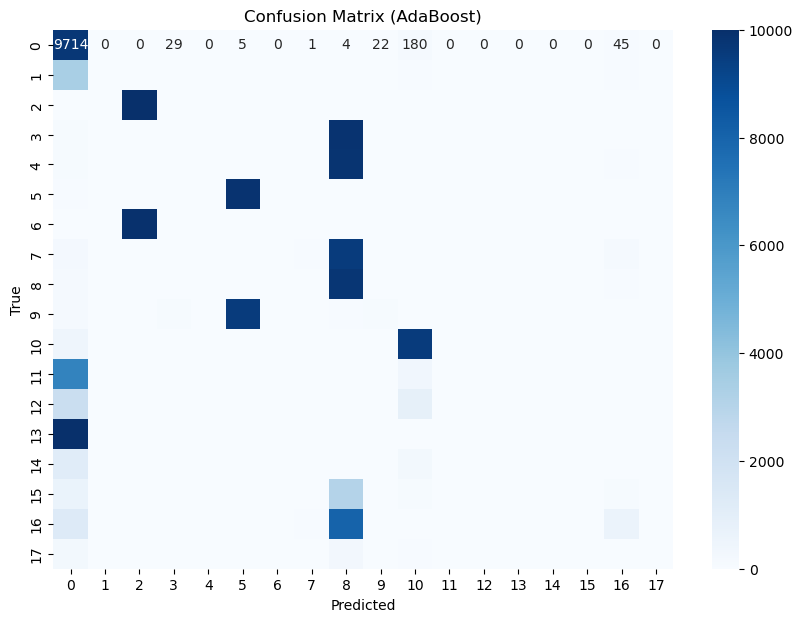


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.9715
  Precision: 0.9710
  Recall:    0.9715
  F1-score:  0.9711

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.96      0.93     10000
           1       0.83      0.84      0.84      3558
           2       1.00      1.00      1.00     10000
           3       1.00      1.00      1.00     10000
           4       1.00      1.00      1.00     10000
           5       1.00      1.00      1.00     10000
           6       1.00      1.00      1.00     10000
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       1.00      1.00      1.00     10000
          10       1.00      1.00      1.00     10000
          11       1.00      1.00      1.00      7208
          12       1.00      1.00      1.00      3181
          13       1.00      1.00      1.00     10000
          14       0.87      0.8

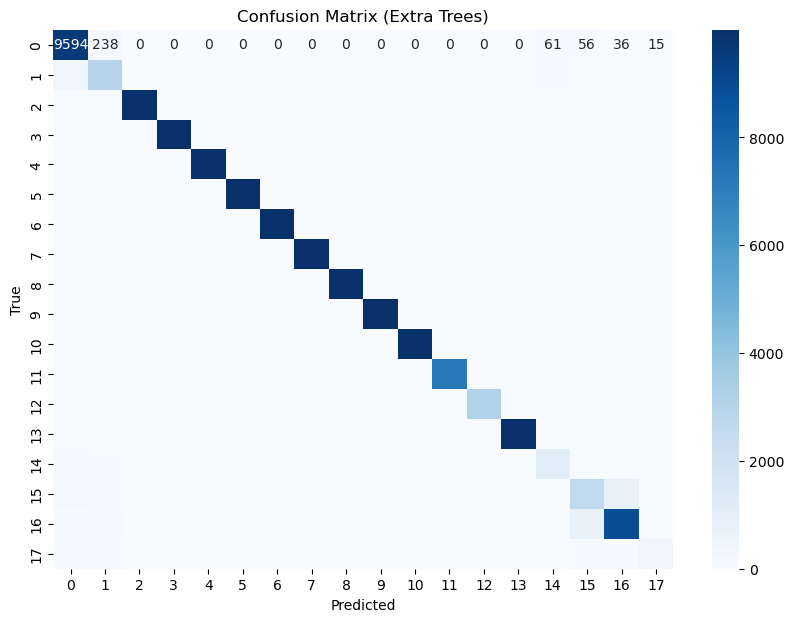


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.3594
  Precision: 0.3740
  Recall:    0.3594
  F1-score:  0.3230

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.27      0.42     10000
           1       0.79      0.05      0.10      3558
           2       0.17      0.00      0.01     10000
           3       0.00      0.00      0.00     10000
           4       0.47      0.87      0.61     10000
           5       0.00      0.00      0.00     10000
           6       0.46      0.90      0.61     10000
           7       0.44      0.43      0.44     10000
           8       0.08      0.02      0.03     10000
           9       0.47      0.49      0.48     10000
          10       0.76      0.84      0.80     10000
          11       0.69      0.44      0.54      7208
          12       0.01      0.02      0.02      3181
          13       0.12      0.35      0.18     10000
          14       0.00      0.00      0.00      1375
        

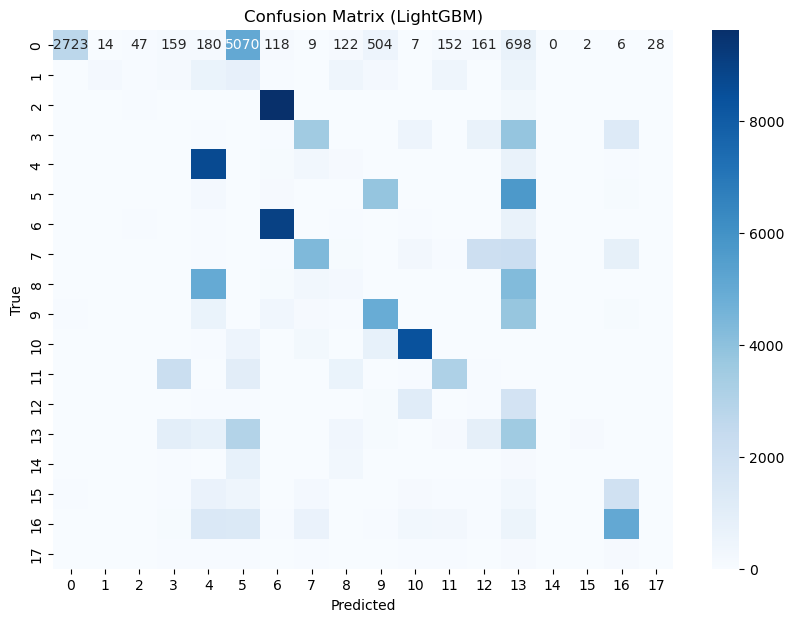


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.9665
  Precision: 0.9657
  Recall:    0.9665
  F1-score:  0.9657

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.97      0.92     10000
           1       0.81      0.80      0.80      3558
           2       1.00      1.00      1.00     10000
           3       1.00      1.00      1.00     10000
           4       1.00      1.00      1.00     10000
           5       1.00      1.00      1.00     10000
           6       1.00      1.00      1.00     10000
           7       1.00      1.00      1.00     10000
           8       1.00      1.00      1.00     10000
           9       1.00      1.00      1.00     10000
          10       1.00      1.00      1.00     10000
          11       1.00      1.00      1.00      7208
          12       1.00      1.00      1.00      3181
          13       1.00      1.00      1.00     10000
          14       0.85      0.69     

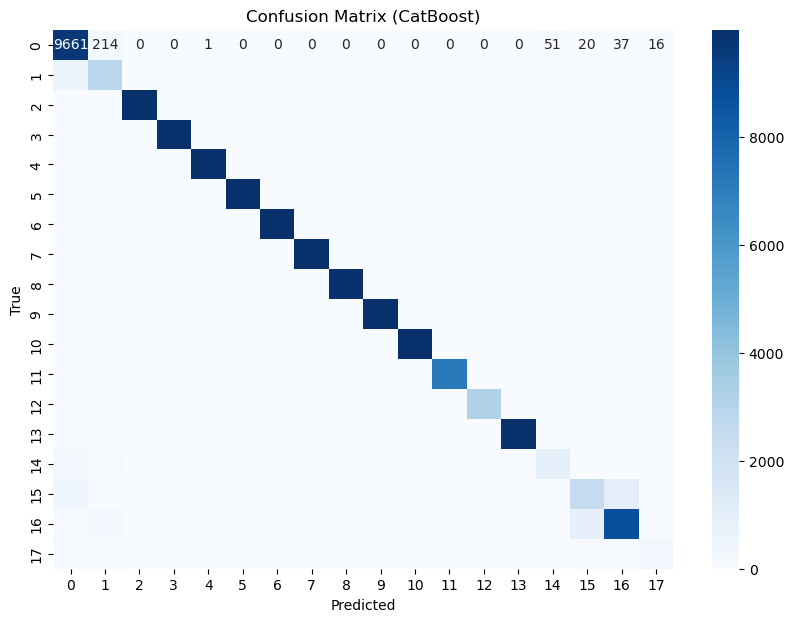


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.929298   0.924228  0.929298  0.919055
Random Forest        0.973878   0.973425  0.973878  0.973553
XGBoost              0.972992   0.972827  0.972992  0.972816
KNN                  0.947084   0.946492  0.947084  0.946045
Naive Bayes          0.706181   0.774554  0.706181  0.665112
Decision Tree        0.947592   0.952907  0.947592  0.946290
AdaBoost             0.354456   0.305976  0.354456  0.221244
Extra Trees          0.971476   0.970971  0.971476  0.971088
LightGBM             0.359353   0.374042  0.359353  0.322981
CatBoost             0.966529   0.965741  0.966529  0.965662


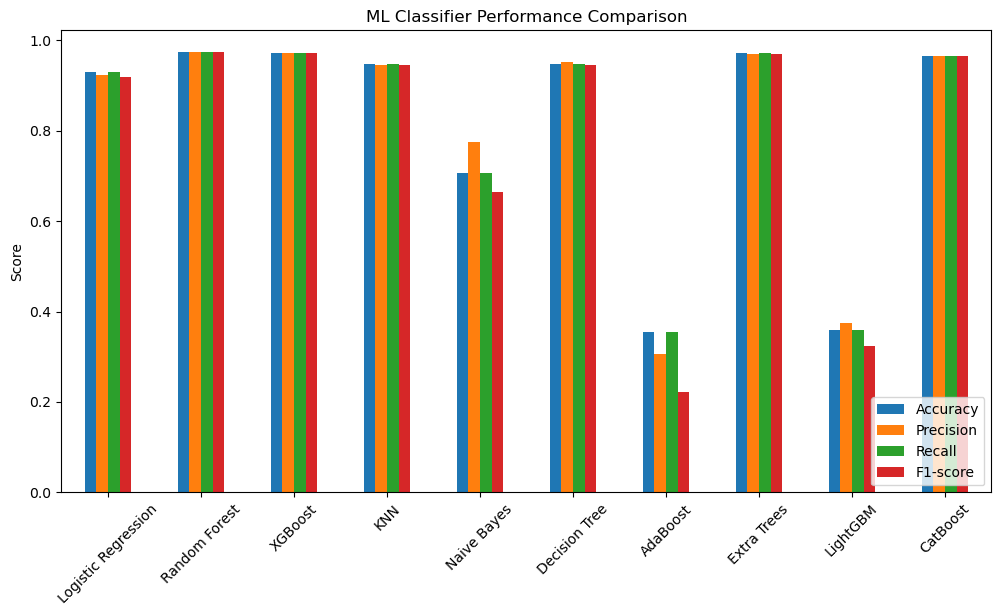

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = encoder.classes_

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"ML-Multi-Attack/Multiclass-ml-{name}.pdf")   # <-- save as PDF
    plt.show()


# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack/Multi-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\

Logistic Regression Avg Performance:
  Accuracy:  0.9270
  Precision: 0.9208
  Recall:    0.9270
  F1-score:  0.9162

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.9689
  Precision: 0.9685
  Recall:    0.9689
  F1-score:  0.9680

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [11:45:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [11:47:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [11:49:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [11:51:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.9686
  Precision: 0.9685
  Recall:    0.9686
  F1-score:  0.9678

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.9438
  Precision: 0.9431
  Recall:    0.9438
  F1-score:  0.9424

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.7469
  Precision: 0.8006
  Recall:    0.7469
  F1-score:  0.7113

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.9453
  Precision: 0.9461
  Recall:    0.9453
  F1-score:  0.9421

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.3328
  Precision: 0.2572
  Recall:    0.3328
  F1-score:  0.2065

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Performance:
  Accuracy:  0.9673
  Precision: 0.9669
  Recall:    0.9673
  F1-score:  0.9665

🔹 Training LightGBM with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.4364
  Precision: 0.5074
  Recall:    0.4364
  F1-score:  0.3992

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.9630
  Precision: 0.9620
  Recall:    0.9630
  F1-score:  0.9616

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.927021   0.920825  0.927021  0.916236
Random Forest        0.968871   0.968529  0.968871  0.967990
XGBoost              0.968576   0.968453  0.968576  0.967831
KNN                  0.943751   0.943150  0.943751  0.942420
Naive Bayes          0.746931   0.800638  0.746931  0.711261
Decision Tree        0.945278   0.946087  0.945278  0.942115
AdaBoost             0.332845   0.257153  0.332845  0.206476
Extra Trees          0.967314   0.966862  0.967314  0.966510
LightGBM             0.436425   0.507425  0.436425  0.399216
CatBoost             0.963037   0.962027  0.963037  0.961560


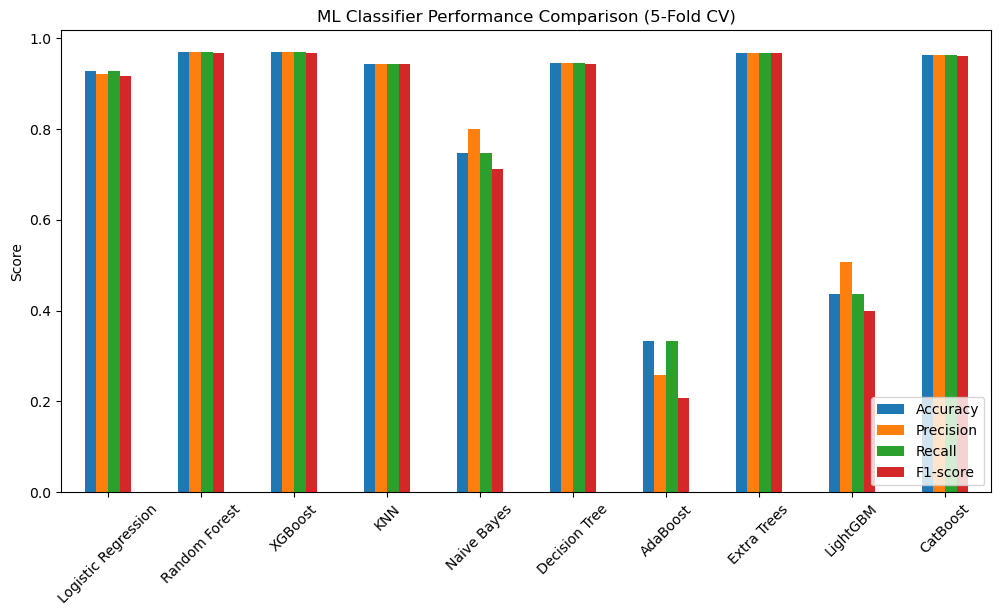

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"ML-Multi-Attack/Multi-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack/Multi-ml-compare-5fold.pdf")
plt.show()
